# Evaluation metrics

In [1]:
# Let's start with the simplest and usually more important one: accuracy

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("churn_telco_data.csv")
df.TotalCharges = pd.to_numeric(df.TotalCharges, errors='coerce')
df.TotalCharges = df.TotalCharges.fillna(0)
df.Churn = (df.Churn == "Yes").astype(int)


df_train_full, df_test = train_test_split(
    df, test_size=0.20, random_state=1)
df_train, df_valid = train_test_split(df_train_full, shuffle=False, test_size=0.25)


y_train = df_train.Churn.values
y_train_full = df_train_full.Churn.values
y_valid = df_valid.Churn.values
y_test = df_test.Churn.values

# del df_train["Churn"]
# del df_valid["Churn"]
# del df_test["Churn"]

all_features = list(df.columns)
all_features.remove("Churn") # In this experiment, we use Churn as a label for prediction not as a feature. 
all_features.remove("customerID") # customerID is not a real useful feature. It doesn't tell anything about the customer at all. 
# print(all_features)
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = list(set(all_features) - set(numeric_features))
# print(categorical_features)

dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical_features + numeric_features].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_valid[categorical_features + numeric_features].to_dict(orient='records')
X_val = dv.transform(val_dict)


model = LogisticRegression(random_state=1, max_iter=5000).fit(X_train, y_train)

In [2]:
# The accuracy of the model is: 

model.score(X_val, y_valid)

0.8026969481902059

In [3]:
# finding accuracy ourselves:

(model.predict(X_val) == y_valid).sum()/len(X_val)

# or simply
# (model.predict(X_val) == y_valid).mean()

np.float64(0.8026969481902059)

In [4]:
# but there is a problem here. Imagine that we have a dummy model:

y_valid

array([0, 0, 0, ..., 1, 1, 0], shape=(1409,))

In [5]:
dummy_model = np.zeros_like(y_valid)
dummy_model

array([0, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [6]:
# The following means that even a dummy model gives us 73 percent
# accuracy. this is because our data is not balanced. 

(dummy_model == y_valid).mean()

np.float64(0.730305180979418)

In [7]:
# So, either we should balance our data or we should consider other
# evaluation criteria as well. 

# Let's move the threshold 

((model.predict_proba(X_val)[:, 1]> 0.5) == y_valid).mean()

np.float64(0.8026969481902059)

In [8]:
threshold = np.linspace(0, 1, 5000)

accuracies = []
max_acc = 0

for t in threshold:
    acc = ((model.predict_proba(X_val)[:, 1]> t) == y_valid).mean()
    accuracies.append((acc, t))

print(max(accuracies))

(np.float64(0.8055358410220014), np.float64(0.5037007401480296))


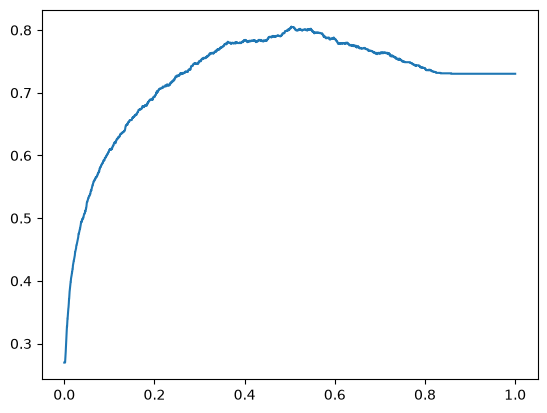

In [9]:
import matplotlib.pyplot as plt

plt.plot(threshold, [accuracies[i][0] for i in range(len(accuracies))])

In [10]:
(model.predict_proba(X_val)[:, 1]< 0.5)

array([ True,  True,  True, ..., False,  True,  True], shape=(1409,))

In [11]:
(model.predict_proba(X_val)[:, 1]> 0.45)

array([False, False, False, ...,  True, False, False], shape=(1409,))

In [12]:
# some probabilities are around the 0.5. 

((model.predict_proba(X_val)[:, 1]< 0.55) & (model.predict_proba(X_val)[:, 1]> 0.45)).sum()

np.int64(97)

In [13]:
# Using sklearn instead of scratch

from sklearn.metrics import accuracy_score

accuracy_score(y_valid, model.predict(X_val))

0.8026969481902059

In [14]:
# Note:

((model.predict_proba(X_val)[:,1] > 1) == y_valid).mean()

# So, even with prediction all equal to 0 (not churn) we get more that 50 percent of accuracy. 

np.float64(0.730305180979418)

In [15]:
# our dataset is not balanced

from collections import Counter

Counter(y_valid)

Counter({np.int64(0): 1029, np.int64(1): 380})

In [16]:
# So, accuracy for imbalanced data can be quite misleading



# Confusion matrix

In [17]:
y_pred = model.predict(X_val)
y_pred

array([0, 0, 0, ..., 1, 0, 0], shape=(1409,))

In [18]:
# TP is the sum of predictions that are 1 (i.e. positive) and they are true as well. 
#(Please provide ven diagram for showing the concept; you can consider a
# circle with four part or other diagram that you think it is appropriate)


TP = (y_pred == y_valid) & (y_pred == 1) 
TP = TP.sum()
TP

np.int64(211)

In [19]:
# TN

#(Please provide ven diagram for showing the concept; you can consider a
# circle with four part or other diagram that you think it is appropriate)

TN =  (y_pred == y_valid) & (y_pred == 0)
TN = TN.sum()
TN

np.int64(920)

In [20]:
FP = (y_pred != y_valid) & (y_pred == 1)
FP = FP.sum()
FP

np.int64(109)

In [21]:
FN = (y_pred != y_valid) & (y_pred == 0)
FN = FN.sum()
FN

np.int64(169)

In [22]:
from sklearn.metrics import confusion_matrix
#(Please provide ven diagram for showing the concept; you can consider a
# circle with four part or other diagram that you think it is appropriate)

confusion_matrix(y_true=y_valid, y_pred=y_pred)

tn, fp, fn, tp = confusion_matrix(y_true=y_valid, y_pred=y_pred).ravel().tolist()
tn, fp, fn, tp

(920, 109, 169, 211)

In [23]:
assert tn+fp+fn+tp == len(y_pred)

In [24]:
confusion_mat = confusion_matrix(y_true=y_valid, y_pred=y_pred)

(confusion_mat/confusion_mat.sum()).round(3)

array([[0.653, 0.077],
       [0.12 , 0.15 ]])

In [25]:
# # something for later in multiclass classification. In this case we have the idea of one-vs-rest
# from sklearn.metrics import multilabel_confusion_matrix


# y_true = [2, 0, 2, 2, 0, 1]
# y_pred = [0, 0, 2, 2, 0, 2]


# matrices = multilabel_confusion_matrix(
#     y_true, y_pred, labels=[0, 1, 2]
# )

# for label, matrix in zip([0, 1, 2], matrices):
#     tn, fp, fn, tp = matrix.ravel()
#     print(label, tn, fp, fn, tp)

# # seems a little bit confusing because maybe for example for class 0, you expect that fn = 1 because we have 1 in y_true that the prediction 
# # is 2 and maybe we want to consider this as a fn but ....

# Accuracy, Precision, and Recall

In [26]:
accuracy = (tp + tn)/(tp + tn + fp + fn)
accuracy

0.8026969481902059

In [27]:
# Precision tell us "how many positive predictions turned out to be correct". A precise model can be like a child that precisely 
# determine positive answer but maybe he or she just give us a few of positives. I mean a person that is precise maybe they
# give us just some few positives. So, being precise is not the whole story. A model can be a precise model (give an example) but not a good
# model because ... . Anyway, precision is an evaluation metric that we should consider especially when we have imbalanced data. 

precision = tp/(tp + fp)
precision

0.659375

In [28]:
# Recall is the ratio of correctly identified positive examples. give example for churn etc. (Please provide ven diagram for showing the concept; you can consider a
# circle with four part or other diagram that you think it is appropriate)

# Note: recall alone is not enough. A model that predict everything as positive has 100 percent recall (why?) but it's precision is low. 

recall = tp/(tp + fn)
recall

0.5552631578947368

In [29]:
# Question: what is the relation between accuracy, precision, and recall? can we obtain one from others or they are independent evaluations? 

In [30]:
# Question: What is the difference between precision and accuracy? Based on the names and intuition they seem to be the same. 

In [31]:
# It seems that precision is accuracy among positives. 

In [32]:
# note: the interpretation of (1-recall) is "the failed to identified positive examples." What is the interpretation of (1- precision)?

In [33]:
# In the churn example: precision is 65 percent. and 1-65=45 means that we are offering discount to 45 percent while they didn't plan to leave us
# Also, the recall is 55 percent. 1-55=45 means that we failed to give gift and discount to 45 percent of our customers and we have loosed them. 

# So, based on these observation, can we don't consider accuracy at all? does it give us a useful info? 



In [34]:
# Note: In our Churn example, when precision is for example 60, it means we are giving discount to 40 percent of our customer
# while they didn't want to leave us. So we are wasting our money (maybe!)

# When recall is for example 60, it means that we have forgotten 40 percent of customers and didn't get them a discount and they left us. 

# When we have imballanced data, accuracy alone is not a good metric because even some dummy models can have good accuracies in this case. 

In [35]:
# I thought in multi class classification (for example MNIST dataset), precision is the same as class accuracies. But it seems it's not. 

# So, my question is this: why don't they consider precision and recall in research papers when they are working with MNIST, Cifar, etc. benchmark?



# ROC curve

In [36]:
y_true = y_valid


# false positive rate for different threshold
def FPR(t):
    y_pred = (model.predict_proba(X_val)[:, 1] > t)
    FP = ((y_pred != y_true) & (y_pred == 1)).sum()
    TN = ((y_pred == y_true) & (y_pred == 0)).sum()
    return FP/(FP + TN)

# true positive (or recall) rate.
def TPR(t):
    y_pred = (model.predict_proba(X_val)[:, 1] > t)
    TP = ((y_pred == y_true) & (y_pred == 1)).sum()
    FN = ((y_pred != y_true) & (y_pred == 0)).sum()
    return TP/(TP + FN)



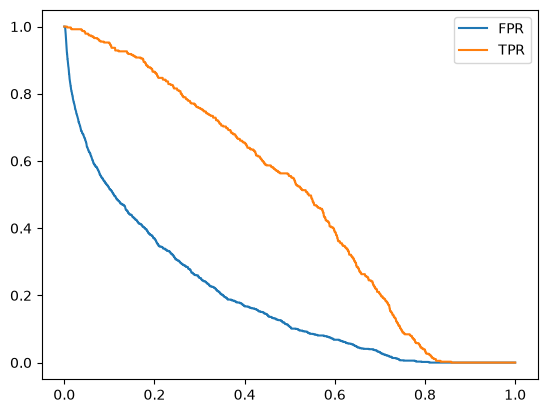

In [37]:
plt.plot(threshold, [FPR(t) for t in threshold], label="FPR")
plt.plot(threshold, [TPR(t) for t in threshold], label="TPR")
plt.legend()

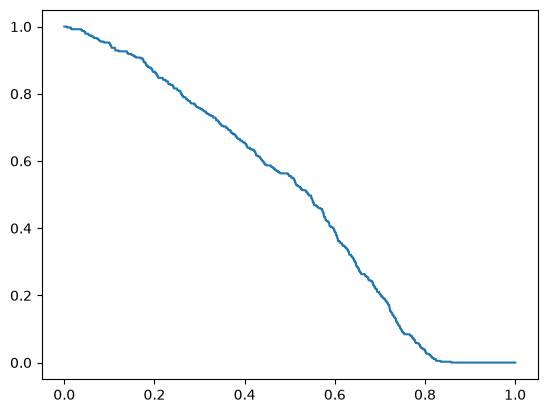

In [38]:
plt.plot(threshold, [TPR(t) for t in threshold])

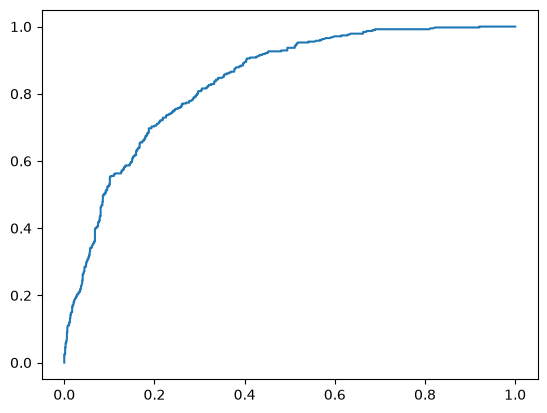

In [39]:
# roc curve

threshold = np.linspace(start=0, stop=1, num=5000)


plt.plot([FPR(t) for t in threshold], [TPR(t) for t in threshold])

In [40]:
# Let's do it in a maybe more structured way using df and pandas

def confusion(t):
    y_pred = (model.predict_proba(X_val)[:, 1] > t)
    tp = ((y_pred == y_true) & (y_pred == 1)).sum()
    tn = ((y_pred == y_true) & (y_pred == 0)).sum()
    fp = ((y_pred != y_true) & (y_pred == 1)).sum()
    fn = ((y_pred != y_true) & (y_pred == 0)).sum()
    return t, tp, fp, fn, tn



scores = [confusion(t) for t in threshold]

columns = ["threshold", "tp", "fp", "fn", "tn"]
df_scores = pd.DataFrame(scores, columns = columns)
df_scores



,threshold,tp,fp,fn,tn
0,0.0000,380,1029,0,0
1,0.0002,380,1029,0,0
2,0.0004,380,1029,0,0
3,0.0006,380,1029,0,0
4,0.0008,380,1029,0,0
...,...,...,...,...,...
4995,0.9992,0,0,380,1029
4996,0.9994,0,0,380,1029
4997,0.9996,0,0,380,1029
4998,0.9998,0,0,380,1029


In [41]:
df_scores['fpr'] = df_scores.fp/(df_scores.fp + df_scores.tn)
df_scores['tpr'] = df_scores.tp/(df_scores.tp + df_scores.fn)
df_scores

,threshold,tp,fp,fn,tn,fpr,tpr
0,0.0000,380,1029,0,0,1.0,1.0
1,0.0002,380,1029,0,0,1.0,1.0
2,0.0004,380,1029,0,0,1.0,1.0
3,0.0006,380,1029,0,0,1.0,1.0
4,0.0008,380,1029,0,0,1.0,1.0
...,...,...,...,...,...,...,...
4995,0.9992,0,0,380,1029,0.0,0.0
4996,0.9994,0,0,380,1029,0.0,0.0
4997,0.9996,0,0,380,1029,0.0,0.0
4998,0.9998,0,0,380,1029,0.0,0.0


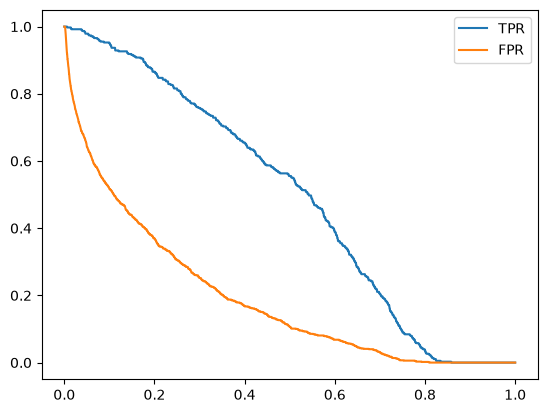

In [42]:
plt.plot(df_scores.threshold, df_scores.tpr, label="TPR")
plt.plot(df_scores.threshold, df_scores.fpr, label="FPR")
plt.legend()

In [43]:
# Note: both cures will decrease. We like that FPR to decrease (and faster decrease is better. Why?) but we want to prevent 
# TPR to decrease suddenly. 

# Random Model

In [44]:
y_pred_random = np.random.rand(y_pred.shape[0]) # should I use np.random.uniform or np.random.rand????
# y_pred_random
((y_pred_random > 0.5) == y_pred).mean()

np.float64(0.48899929027679206)

In [45]:
def confusion_random(t):
    y_pred = (y_pred_random > t)
    tp = ((y_pred == y_true) & (y_pred == 1)).sum()
    tn = ((y_pred == y_true) & (y_pred == 0)).sum()
    fp = ((y_pred != y_true) & (y_pred == 1)).sum()
    fn = ((y_pred != y_true) & (y_pred == 0)).sum()
    return t, tp, fp, fn, tn

scores_random = [confusion_random(t) for t in threshold]

columns = ["threshold", "tp", "fp", "fn", "tn"]
df_scores_random = pd.DataFrame(scores_random, columns = columns)


df_scores_random['fpr'] = df_scores_random.fp/(df_scores_random.fp + df_scores_random.tn)
df_scores_random['tpr'] = df_scores_random.tp/(df_scores_random.tp + df_scores_random.fn)
df_scores_random

,threshold,tp,fp,fn,tn,fpr,tpr
0,0.0000,380,1029,0,0,1.0,1.000000
1,0.0002,380,1029,0,0,1.0,1.000000
2,0.0004,380,1029,0,0,1.0,1.000000
3,0.0006,380,1029,0,0,1.0,1.000000
4,0.0008,380,1029,0,0,1.0,1.000000
...,...,...,...,...,...,...,...
4995,0.9992,1,0,379,1029,0.0,0.002632
4996,0.9994,0,0,380,1029,0.0,0.000000
4997,0.9996,0,0,380,1029,0.0,0.000000
4998,0.9998,0,0,380,1029,0.0,0.000000


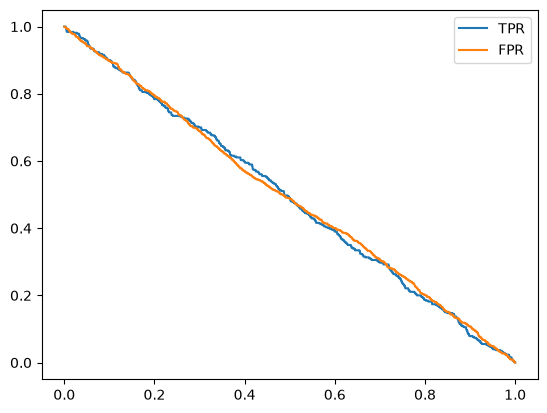

In [46]:
plt.plot(df_scores_random.threshold, df_scores_random.tpr, label="TPR")
plt.plot(df_scores_random.threshold, df_scores_random.fpr, label="FPR")
plt.legend()

you can see the above and see that in a random model the blue line and red line decrease like each other. We expect that the blue line be in top and the orange line decrease suddenly etc. (bring correct explanation)

# Ideal model

## Now lets create an ideal model and see the curves in the case of ideal model. 

## The definition of an Ideal model is: There exists a threshold such that for that FPR=0 (or equivalently FP=0 for all) and TPR = 1 (or equivalently TP = 1 for all). 

## It seems that it is not ideal model. In fact it is related to our data to be ideal and then we can find that threshold. 

In [47]:
# y_ideal = ?

num_pos = (y_valid == 1).sum()
num_neg = (y_valid == 0).sum()
num_pos, num_neg

(np.int64(380), np.int64(1029))

In [48]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [49]:
t = num_neg/(num_neg + num_pos)
t

np.float64(0.730305180979418)

In [50]:
y_pred_ideal = np.linspace(0, 1, len(y_ideal))
y_pred_ideal


def confusion_ideal(t):
    y_pred = (y_pred_ideal > t)
    tp = ((y_pred == y_ideal) & (y_pred == 1)).sum()
    tn = ((y_pred == y_ideal) & (y_pred == 0)).sum()
    fp = ((y_pred != y_ideal) & (y_pred == 1)).sum()
    fn = ((y_pred != y_ideal) & (y_pred == 0)).sum()
    return t, tp, fp, fn, tn

scores_ideal = [confusion_ideal(t) for t in threshold]

columns = ["threshold", "tp", "fp", "fn", "tn"]
df_scores_ideal = pd.DataFrame(scores_ideal, columns = columns)


df_scores_ideal['fpr'] = df_scores_ideal.fp/(df_scores_ideal.fp + df_scores_ideal.tn)
df_scores_ideal['tpr'] = df_scores_ideal.tp/(df_scores_ideal.tp + df_scores_ideal.fn)
df_scores_ideal

,threshold,tp,fp,fn,tn,fpr,tpr
0,0.0000,380,1028,0,1,0.999028,1.000000
1,0.0002,380,1028,0,1,0.999028,1.000000
2,0.0004,380,1028,0,1,0.999028,1.000000
3,0.0006,380,1028,0,1,0.999028,1.000000
4,0.0008,380,1027,0,2,0.998056,1.000000
...,...,...,...,...,...,...,...
4995,0.9992,2,0,378,1029,0.000000,0.005263
4996,0.9994,1,0,379,1029,0.000000,0.002632
4997,0.9996,1,0,379,1029,0.000000,0.002632
4998,0.9998,1,0,379,1029,0.000000,0.002632


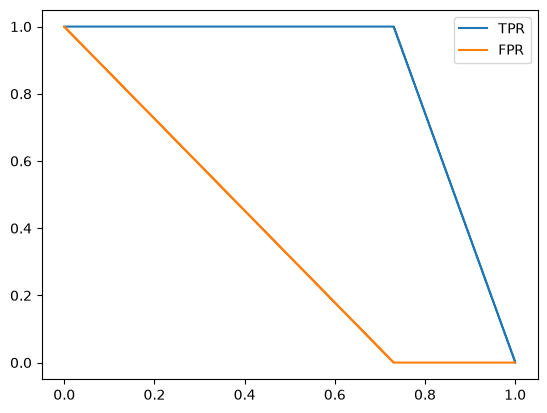

In [51]:
plt.plot(df_scores_ideal.threshold, df_scores_ideal.tpr, label="TPR")
plt.plot(df_scores_ideal.threshold, df_scores_ideal.fpr, label="FPR")
plt.legend()

# note that we don't have such validation set and ideal prediction in action. It is just an ideal situation. In this case, it a threshold (here 0.73) the model predict 100 percent accuracy as well as precision and recall because we don't have fp and fn at all. 

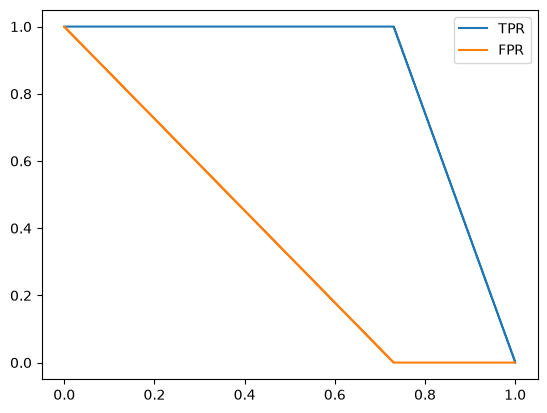

In [52]:
# We could create a function to prevent some repetitive codes

def fpr_tpr_dataframe(y_true, y_pred_prob, num_threshold=5000):
    """y_true is 0 and 1's. y_pred_prob is probabilities"""

    threshold = np.linspace(0, 1, num_threshold)

    scores = []

    for t in threshold:
        y_pred = (y_pred_prob > t)
        tp = ((y_pred == y_true) & (y_pred == 1)).sum()
        tn = ((y_pred == y_true) & (y_pred == 0)).sum()
        fp = ((y_pred != y_true) & (y_pred == 1)).sum()
        fn = ((y_pred != y_true) & (y_pred == 0)).sum()
        scores.append((t, tp, fp, fn, tn))

    columns = ["threshold", "tp", "fp", "fn", "tn"]
    df_scores = pd.DataFrame(scores, columns = columns)

    df_scores['fpr'] = df_scores.fp/(df_scores.fp + df_scores.tn)
    df_scores['tpr'] = df_scores.tp/(df_scores.tp + df_scores.fn)
    return df_scores

# now:

num_pos = (y_valid == 1).sum()
num_neg = (y_valid == 0).sum()
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_pred_ideal = np.linspace(0, 1, len(y_ideal))

df_scores_ideal = fpr_tpr_dataframe(y_true=y_ideal, y_pred_prob=y_pred_ideal)

plt.plot(df_scores_ideal.threshold, df_scores_ideal.tpr, label="TPR")
plt.plot(df_scores_ideal.threshold, df_scores_ideal.fpr, label="FPR")
plt.legend()

        
    

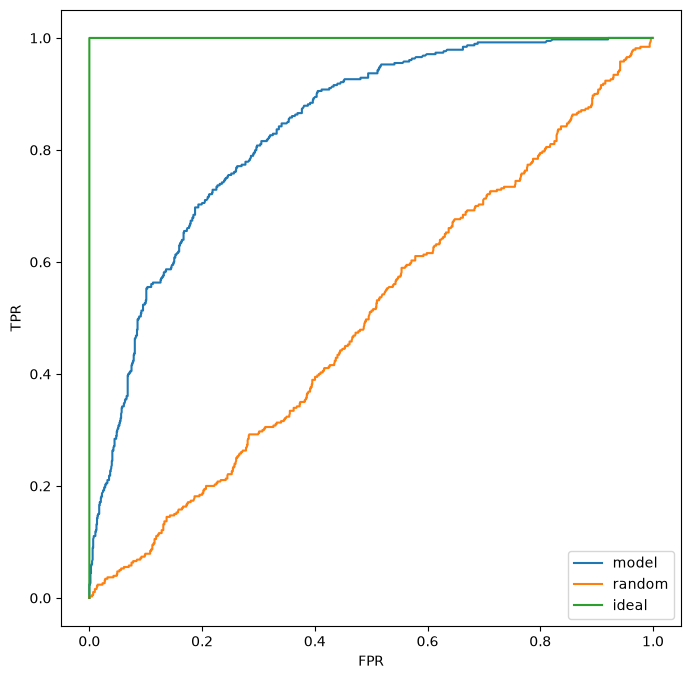

In [53]:
plt.figure(figsize=(8, 8))

plt.plot(df_scores.fpr, df_scores.tpr, label='model')
plt.plot(df_scores_random.fpr, df_scores_random.tpr, label='random')
plt.plot(df_scores_ideal.fpr, df_scores_ideal.tpr, label='ideal')

plt.xlabel("FPR")
plt.ylabel("TPR")

plt.legend()

In [54]:
df_scores_ideal.tpr.mean()

np.float64(0.8653384210526316)

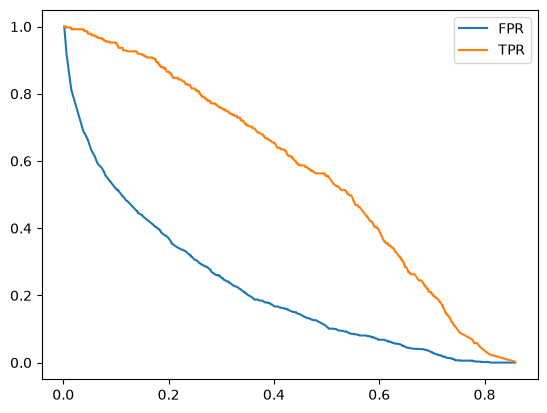

In [55]:
# Plotting ROC curves using sklearn internal functions

from sklearn.metrics import roc_curve

y_valid.shape
# model.predict_proba(X_val).[:, 1]
fpr, tpr, thresholds = roc_curve(y_true=y_valid, y_score=model.predict_proba(X_val)[:,1])
fpr, tpr, thresholds

plt.plot(thresholds, fpr, label="FPR")
plt.plot(thresholds, tpr, label="TPR")
plt.legend()

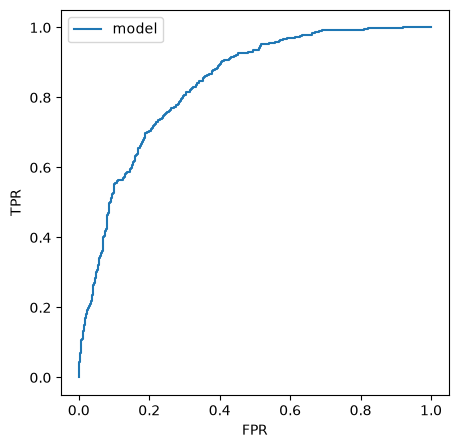

In [56]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label="model")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

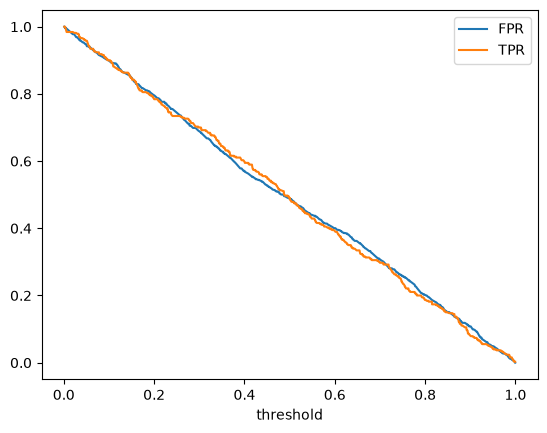

In [57]:

fpr, tpr, thresholds = roc_curve(y_true=y_valid, y_score=y_pred_random)
fpr, tpr, thresholds

plt.plot(thresholds, fpr, label="FPR")
plt.plot(thresholds, tpr, label="TPR")
plt.xlabel("threshold")
plt.legend()

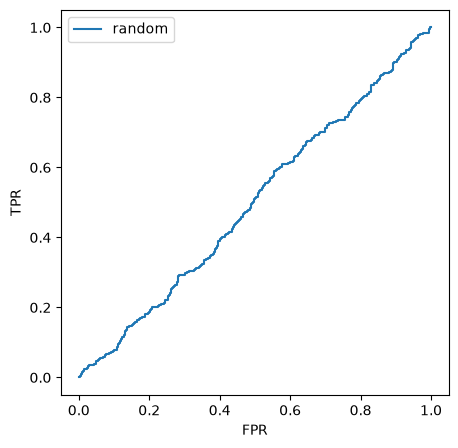

In [58]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label="random")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

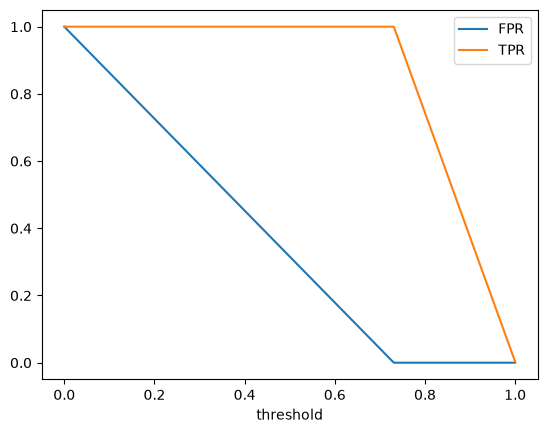

In [59]:
fpr, tpr, thresholds = roc_curve(y_true=y_ideal, y_score=y_pred_ideal)
fpr, tpr, thresholds

plt.plot(thresholds, fpr, label="FPR")
plt.plot(thresholds, tpr, label="TPR")
plt.xlabel("threshold")
plt.legend()

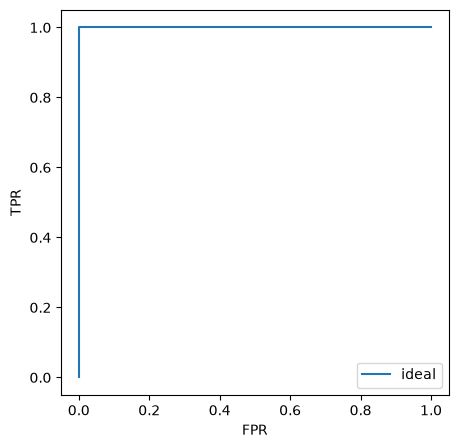

In [60]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label="ideal")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

# AUC of ROC

In [61]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_true=y_valid, y_score=model.predict_proba(X_val)[:,1])

0.8361490460845992

In [62]:
roc_auc_score(y_true=y_ideal, y_score=y_pred_ideal)

1.0

In [63]:
roc_auc_score(y_true=y_valid, y_score=y_pred_random)

0.49796429850135543

# AUC interpretation: this number has a nice interpretation. It shows if we randomly choose a positive instance and a negative instance, then the probability of that the positive instance has a greater score than the negative instance is AUC. 

# why do we have this interpretation? explain it


In [64]:
# let's see it in our example:

y_pred = model.predict_proba(X_val)[:, 1]

pos = y_pred[y_valid==1]
neg = y_pred[y_valid==0]

num_1 = np.random.randint(low=0, high=len(pos))
num_2 = np.random.randint(low=0, high=len(neg))

pos[num_1], neg[num_2]

success = 0

for i in range(10000):
    num_1 = np.random.randint(low=0, high=len(pos))
    num_2 = np.random.randint(low=0, high=len(neg))

    if pos[num_1] >= neg[num_2]:
        success += 1


print(success/10000) # this is the same as auc of roc

## but why does this happen? 


0.8424


In [65]:
# doing in vectorized form with numpy

n = 100000

pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size = n)

(pos[pos_ind] > neg[neg_ind]).mean()


np.float64(0.83651)

# k-fold Cross-Validation 

In [85]:
def train(df, y_train, c=1.0):

    dicts = df[categorical_features + numeric_features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(max_iter=5000, C=c) # c is for regularization
    model.fit(X_train, y_train)

    return dv, model 

In [86]:
dv, model = train(df_train, y_train)

In [68]:
model

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [87]:
def predict(df, dv, model):

    dicts = df[categorical_features + numeric_features].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred

predict(df_valid, dv, model)

array([0.17212969, 0.00487718, 0.66443206, 0.07531187, 0.59168685,
       0.30068406, 0.29238437, 0.22964513, 0.00278599, 0.0849787 ,
       0.05011086, 0.01243499, 0.48557353, 0.73380326, 0.33382463,
       0.19737383, 0.64861104, 0.26390078, 0.27872446, 0.03038422,
       0.68152676, 0.02434055, 0.00294541, 0.50570547, 0.74908245,
       0.08326105, 0.7277258 , 0.02878685, 0.66826837, 0.00981968,
       0.0368883 , 0.00850013, 0.43816635, 0.56043403, 0.1372071 ,
       0.0315249 , 0.52390243, 0.15304409, 0.75158585, 0.62687333,
       0.32840779, 0.28422212, 0.73463163, 0.00708845, 0.00207042,
       0.57620627, 0.4167296 , 0.30884341, 0.08940828, 0.48641531,
       0.00741537, 0.0063553 , 0.54683744, 0.60513749, 0.19998511,
       0.08457791, 0.00470419, 0.43414587, 0.0192914 , 0.00393598,
       0.01989807, 0.69180857, 0.27439523, 0.06238666, 0.64589758,
       0.03254832, 0.73171348, 0.07730523, 0.18154318, 0.01644351,
       0.43373707, 0.39066294, 0.5087012 , 0.19229908, 0.70373

In [88]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=1)
print(type(kfold))

train_idx, valid_idx = next(kfold.split(df_train_full))

assert len(train_idx) + len(valid_idx) == len(df_train_full)

<class 'sklearn.model_selection._split.KFold'>


In [81]:
# !pip install tqdm  # note: ! shows that this is a batch command. so it is executed like pip install tqdm in the terminal. 

from tqdm.auto import tqdm

areas = []

for train_idx, valid_idx in tqdm(kfold.split(df_train_full)):
    df_train = df_train_full.iloc[train_idx]
    df_valid = df_train_full.iloc[valid_idx]

    y_train = df_train.Churn.values 
    y_valid = df_valid.Churn.values 

    dv, model = train(df_train, y_train)

    y_pred = predict(df_valid, dv, model)
    auc = roc_auc_score(y_true=y_valid, y_score=y_pred)
    areas.append(auc)



0it [00:00, ?it/s]

In [82]:
areas

[0.8496732026143791,
 0.8424659653465347,
 0.8585286447519227,
 0.8332729816476011,
 0.8246588089330025,
 0.841092241092241,
 0.8430804298274177,
 0.8254032258064516,
 0.845872239513858,
 0.861097105979631]

In [83]:
np.mean(areas), np.std(areas)

(np.float64(0.8425144845513038), np.float64(0.01167758552500827))

In [84]:
print('%.3f +- %.3f' % (np.mean(areas), np.std(areas)))

0.843 +- 0.012


In [89]:
# also we can bring regularization term C in the process and see which one is better. 

for c in [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0]:
    
    areas = []

    for train_idx, valid_idx in tqdm(kfold.split(df_train_full)):
        df_train = df_train_full.iloc[train_idx]
        df_valid = df_train_full.iloc[valid_idx]

        y_train = df_train.Churn.values 
        y_valid = df_valid.Churn.values 

        dv, model = train(df_train, y_train, c=c)

        y_pred = predict(df_valid, dv, model)
        auc = roc_auc_score(y_true=y_valid, y_score=y_pred)
        areas.append(auc)

    print('c=%s %.3f +- %.3f' % (c, np.mean(areas), np.std(areas)))


    



0it [00:00, ?it/s]

c=0.0001 0.811 +- 0.012


0it [00:00, ?it/s]

c=0.001 0.826 +- 0.012


0it [00:00, ?it/s]

...

c=0.1 0.842 +- 0.012


0it [00:00, ?it/s]

c=0.5 0.843 +- 0.012


0it [00:00, ?it/s]

c=1.0 0.843 +- 0.012


In [90]:
# now we can choose the best one and train on full train and evaluate on test dataset. do it chat. 

dv, model = train(df_train_full, df_train_full.Churn.values, c=1.0) # the above shows that c=1.0 is the best option

y_pred_test = predict(df_test, dv, model)

((y_pred_test>0.5) == y_test).mean()



np.float64(0.8119233498935415)

In [94]:
auc = roc_auc_score(y_true=y_test, y_score=y_pred_test)
auc

0.8584925845277174

In [ ]:
# when should we use k-fold technique?